# Is Fandango Inflating Movie Ratings?

An exploratory data analysis of Fandango's displayed star ratings vs. Rotten Tomatoes, Metacritic and IMDb.

**Background.** In 2015, FiveThirtyEight published *"Be Suspicious Of Online Movie Ratings, Especially Fandango's"*, which suggested that Fandango's star ratings were skewed upward, possibly because the site also sells movie tickets. This notebook recreates that analysis in Python to see whether the data backs it up.

**Data:** [Be Suspicious Of Online Movie Ratings (Kaggle)](https://www.kaggle.com/datasets/mikhail1681/be-suspicious-of-online-movie-ratings)

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn

## Datasets

**`fandango_ratings aggregator.csv`** (504 films)

| Column | Description |
|---|---|
| `FILM` | Movie title, with release year in brackets |
| `STARS` | Star rating *displayed* on Fandango.com |
| `RATING` | Actual average rating, read from the page's HTML |
| `VOTES` | Number of user votes when the data was collected |

**`other ratings aggregators.csv`** (146 films)

| Column | Description |
|---|---|
| `FILM` | Movie title |
| `RottenTomatoes` | Rotten Tomatoes critic score (Tomatometer), 0-100 |
| `RottenTomatoes_User` | Rotten Tomatoes user score, 0-100 |
| `Metacritic` | Metacritic critic score, 0-100 |
| `Metacritic_User` | Metacritic user score, 0-10 |
| `IMDB` | IMDb user score, 0-10 |
| `Metacritic_user_vote_count` | Number of Metacritic user votes |
| `IMDB_user_vote_count` | Number of IMDb user votes |

## Plan

1. Explore the Fandango data
2. Compare Fandango's displayed stars with its own actual ratings
3. Look at how other platforms rate films, and merge the two datasets
4. Compare rating distributions across platforms (after putting everything on a 0-5 scale)
5. Conclusion

## 1. Exploring the Fandango data

In [1]:
# Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
!pip install kagglehub -q
import kagglehub

In [55]:
# Load the Fandango data
DATA_DIR = kagglehub.dataset_download("mikhail1681/be-suspicious-of-online-movie-ratings")
print(DATA_DIR)

fandago = pd.read_csv(f"{DATA_DIR}/fandango_ratings aggregator.csv")

Using Colab cache for faster access to the 'be-suspicious-of-online-movie-ratings' dataset.
/kaggle/input/be-suspicious-of-online-movie-ratings


In [4]:
fandago.head(10)

,FILM,STARS,RATING,VOTES
0,Fifty Shades of Grey (2015),4.0,3.9,34846
1,Jurassic World (2015),4.5,4.5,34390
2,American Sniper (2015),5.0,4.8,34085
3,Furious 7 (2015),5.0,4.8,33538
4,Inside Out (2015),4.5,4.5,15749
5,The Hobbit: The Battle of the Five Armies (2014),4.5,4.3,15337
6,Kingsman: The Secret Service (2015),4.5,4.2,15205
7,Minions (2015),4.0,4.0,14998
8,Avengers: Age of Ultron (2015),5.0,4.5,14846
9,Into the Woods (2014),3.5,3.4,13055


In [5]:
fandago.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 504 entries, 0 to 503
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   FILM    504 non-null    object 
 1   STARS   504 non-null    float64
 2   RATING  504 non-null    float64
 3   VOTES   504 non-null    int64  
dtypes: float64(2), int64(1), object(1)
memory usage: 15.9+ KB


In [6]:
fandago.describe()

,STARS,RATING,VOTES
count,504.000000,504.000000,504.000000
mean,3.558532,3.375794,1147.863095
std,1.563133,1.491223,3830.583136
min,0.000000,0.000000,0.000000
25%,3.500000,3.100000,3.000000
50%,4.000000,3.800000,18.500000
75%,4.500000,4.300000,189.750000
max,5.000000,5.000000,34846.000000


**What stands out:**
- 504 films, no missing values.
- The median vote count is only 18.5, so most films have very few votes. A handful of blockbusters have 30,000+.
- The minimum for both `STARS` and `RATING` is 0, which hints at films with no votes at all. I'll check that below.

### Popularity vs. rating

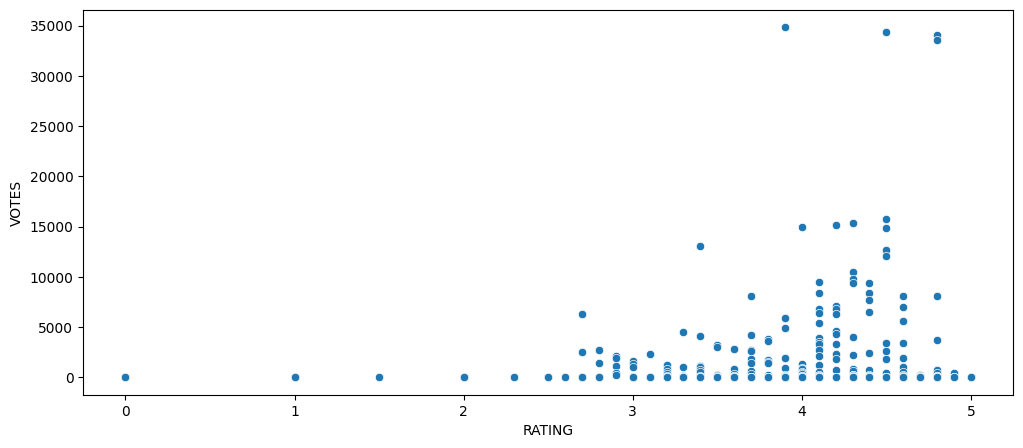

In [7]:
# Does a more popular film (more votes) get a higher rating?
plt.figure(figsize=(12, 5))
sns.scatterplot(data=fandago, x='RATING', y='VOTES');

In [8]:
# Correlation between the numeric columns
fandago.corr(numeric_only=True)

,STARS,RATING,VOTES
STARS,1.000000,0.994696,0.164218
RATING,0.994696,1.000000,0.163764
VOTES,0.164218,0.163764,1.000000


`STARS` and `RATING` are almost perfectly correlated (0.99), which makes sense since they measure the same thing. The correlation between votes and rating is weak (about 0.16), so popularity alone doesn't explain how high a film is rated.

### Release years

In [9]:
# FILM looks like 'Title (Year)', so pull the year out into its own column
fandago['YEAR'] = fandago['FILM'].str[-5:-1]

In [10]:
fandago.head()

,FILM,STARS,RATING,VOTES,YEAR
0,Fifty Shades of Grey (2015),4.0,3.9,34846,2015
1,Jurassic World (2015),4.5,4.5,34390,2015
2,American Sniper (2015),5.0,4.8,34085,2015
3,Furious 7 (2015),5.0,4.8,33538,2015
4,Inside Out (2015),4.5,4.5,15749,2015


In [11]:
# Number of films per release year
fandago.groupby('YEAR')['FILM'].count().sort_values(ascending=False)

,FILM
YEAR,
2015,478
2014,23
1964,1
2012,1
2016,1


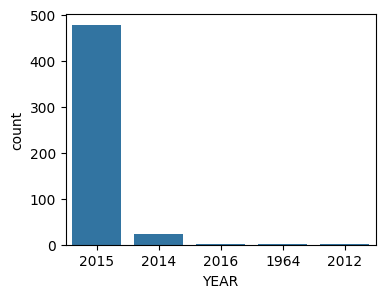

In [12]:
plt.figure(figsize=(4,3))
sns.countplot(data=fandago, x='YEAR');

The dataset is almost entirely 2015 films (478 of 504), so release year won't be a useful factor in the rest of the analysis.

### Most-voted films and films with no votes

In [13]:
# Top 10 films by number of votes
fandago.nlargest(10, 'VOTES')

,FILM,STARS,RATING,VOTES,YEAR
0,Fifty Shades of Grey (2015),4.0,3.9,34846,2015
1,Jurassic World (2015),4.5,4.5,34390,2015
2,American Sniper (2015),5.0,4.8,34085,2015
3,Furious 7 (2015),5.0,4.8,33538,2015
4,Inside Out (2015),4.5,4.5,15749,2015
5,The Hobbit: The Battle of the Five Armies (2014),4.5,4.3,15337,2014
6,Kingsman: The Secret Service (2015),4.5,4.2,15205,2015
7,Minions (2015),4.0,4.0,14998,2015
8,Avengers: Age of Ultron (2015),5.0,4.5,14846,2015
9,Into the Woods (2014),3.5,3.4,13055,2014


In [14]:
# How many films have zero votes?
fandago[fandago['VOTES'] == 0].shape[0]

69

In [15]:
# Keep only films with at least one vote
# (.copy() avoids pandas' SettingWithCopyWarning when we add a column later)
votes_fandago = fandago[fandago['VOTES'] > 0].copy()

69 films have zero votes, so they have no real rating to compare against. I dropped them, which leaves 435 films.

## 2. Displayed stars vs. actual ratings on Fandango

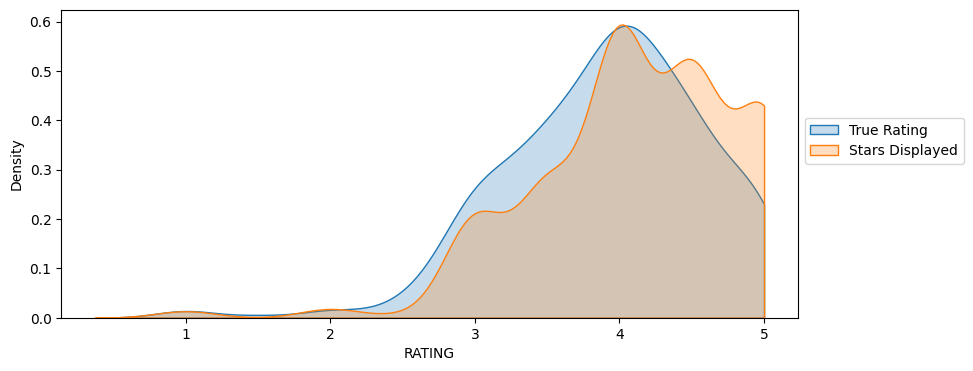

In [16]:
# Distribution of the stars Fandango displays vs. the actual rating from user votes
plt.figure(figsize=(9.5,4))
sns.kdeplot(data=votes_fandago, x='RATING', clip=(0, 5), fill=True, label='True Rating')
sns.kdeplot(data=votes_fandago, x='STARS', clip=(0, 5), fill=True, label='Stars Displayed')
plt.legend(loc=(1.01, 0.5));

The displayed stars are clearly shifted to the right of the actual ratings. Fandango's stars are concentrated between 3 and 5.

In [17]:
# How far apart are the displayed stars and the actual rating?
votes_fandago['STARS_DIFF'] = round(votes_fandago['STARS'] - votes_fandago['RATING'], 1)

In [18]:
votes_fandago

,FILM,STARS,RATING,VOTES,YEAR,STARS_DIFF
0,Fifty Shades of Grey (2015),4.0,3.9,34846,2015,0.1
1,Jurassic World (2015),4.5,4.5,34390,2015,0.0
2,American Sniper (2015),5.0,4.8,34085,2015,0.2
3,Furious 7 (2015),5.0,4.8,33538,2015,0.2
4,Inside Out (2015),4.5,4.5,15749,2015,0.0
...,...,...,...,...,...,...
430,That Sugar Film (2015),5.0,5.0,1,2015,0.0
431,The Intern (2015),5.0,5.0,1,2015,0.0
432,The Park Bench (2015),5.0,5.0,1,2015,0.0
433,The Wanted 18 (2015),5.0,5.0,1,2015,0.0


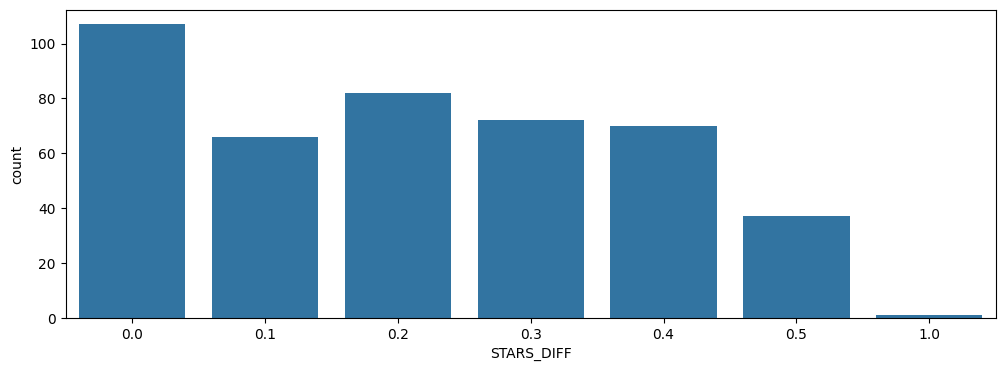

In [19]:
# Distribution of the difference
plt.figure(figsize=(12,4))
sns.countplot(data=votes_fandago, x='STARS_DIFF');

In [20]:
# The one film with a full 1-star gap
votes_fandago[votes_fandago['STARS_DIFF'] == 1]

,FILM,STARS,RATING,VOTES,YEAR,STARS_DIFF
381,Turbo Kid (2015),5.0,4.0,2,2015,1.0


**Takeaway:** the difference is never negative. Fandango's displayed stars are always equal to or higher than the actual rating, never lower. Most gaps are between 0 and 0.5 stars, and the single 1-star gap (*Turbo Kid*) comes from a film with only 2 votes, so I wouldn't read much into it.

## 3. Fandango vs. other platforms

In [22]:
# Load the ratings from the other platforms
other = pd.read_csv(f"{DATA_DIR}/other ratings aggregators.csv")

In [25]:
other.head()

,FILM,RottenTomatoes,RottenTomatoes_User,Metacritic,Metacritic_User,IMDB,Metacritic_user_vote_count,IMDB_user_vote_count
0,Avengers: Age of Ultron (2015),74,86,66,7.1,7.8,1330,271107
1,Cinderella (2015),85,80,67,7.5,7.1,249,65709
2,Ant-Man (2015),80,90,64,8.1,7.8,627,103660
3,Do You Believe? (2015),18,84,22,4.7,5.4,31,3136
4,Hot Tub Time Machine 2 (2015),14,28,29,3.4,5.1,88,19560


In [26]:
other.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 146 entries, 0 to 145
Data columns (total 8 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   FILM                        146 non-null    object 
 1   RottenTomatoes              146 non-null    int64  
 2   RottenTomatoes_User         146 non-null    int64  
 3   Metacritic                  146 non-null    int64  
 4   Metacritic_User             146 non-null    float64
 5   IMDB                        146 non-null    float64
 6   Metacritic_user_vote_count  146 non-null    int64  
 7   IMDB_user_vote_count        146 non-null    int64  
dtypes: float64(2), int64(5), object(1)
memory usage: 9.3+ KB


In [27]:
other.describe()

,RottenTomatoes,RottenTomatoes_User,Metacritic,Metacritic_User,IMDB,Metacritic_user_vote_count,IMDB_user_vote_count
count,146.000000,146.000000,146.000000,146.000000,146.000000,146.000000,146.000000
mean,60.849315,63.876712,58.808219,6.519178,6.736986,185.705479,42846.205479
std,30.168799,20.024430,19.517389,1.510712,0.958736,316.606515,67406.509171
min,5.000000,20.000000,13.000000,2.400000,4.000000,4.000000,243.000000
25%,31.250000,50.000000,43.500000,5.700000,6.300000,33.250000,5627.000000
50%,63.500000,66.500000,59.000000,6.850000,6.900000,72.500000,19103.000000
75%,89.000000,81.000000,75.000000,7.500000,7.400000,168.500000,45185.750000
max,100.000000,94.000000,94.000000,9.600000,8.600000,2375.000000,334164.000000


### Critics vs. users on Rotten Tomatoes

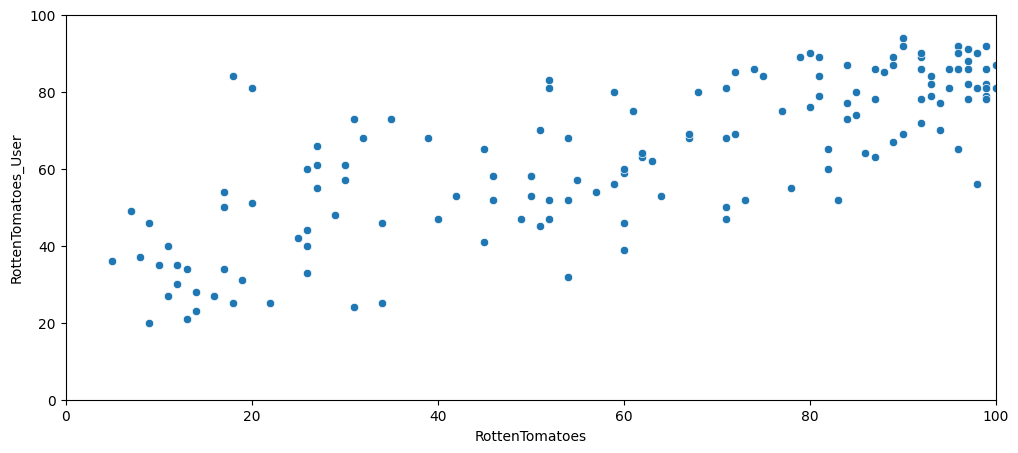

In [28]:
# Critic score vs. user score on Rotten Tomatoes
plt.figure(figsize=(12,5))
plt.xlim(0, 100)
plt.ylim(0, 100)
sns.scatterplot(data=other, x='RottenTomatoes', y='RottenTomatoes_User');

To measure how much critics and users disagree, I calculated `Rotten_Diff = RottenTomatoes - RottenTomatoes_User`:
- Near 0: critics and users agree
- Large positive: critics liked the film much more than users
- Large negative: users liked the film much more than critics

In [29]:
other['Rotten_Diff'] = other['RottenTomatoes'] - other['RottenTomatoes_User']

In [30]:
# Average size of the disagreement, ignoring direction
abs(other['Rotten_Diff']).mean()

np.float64(15.095890410958905)

On average, critics and users on Rotten Tomatoes differ by about 15 points.

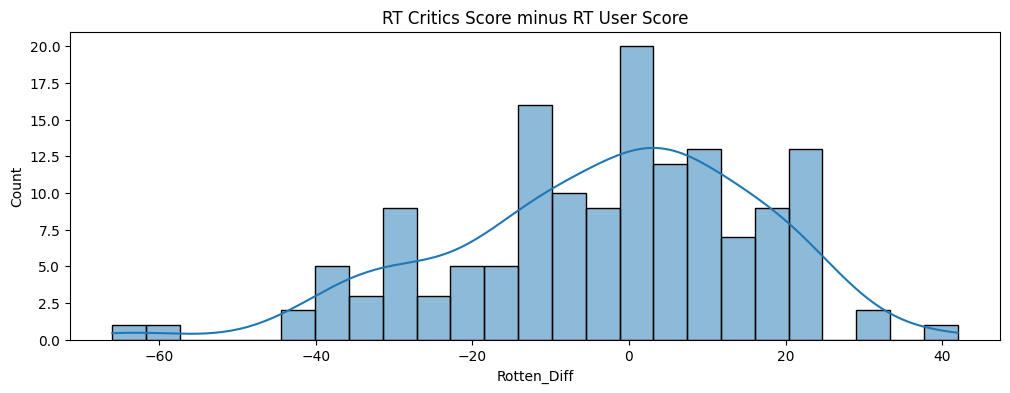

In [31]:
# Distribution of the difference (critic minus user)
fig, ax = plt.subplots(figsize=(12, 4))
sns.histplot(data=other, x='Rotten_Diff', kde=True, bins=25, ax=ax)
ax.set_title('RT Critics Score minus RT User Score');

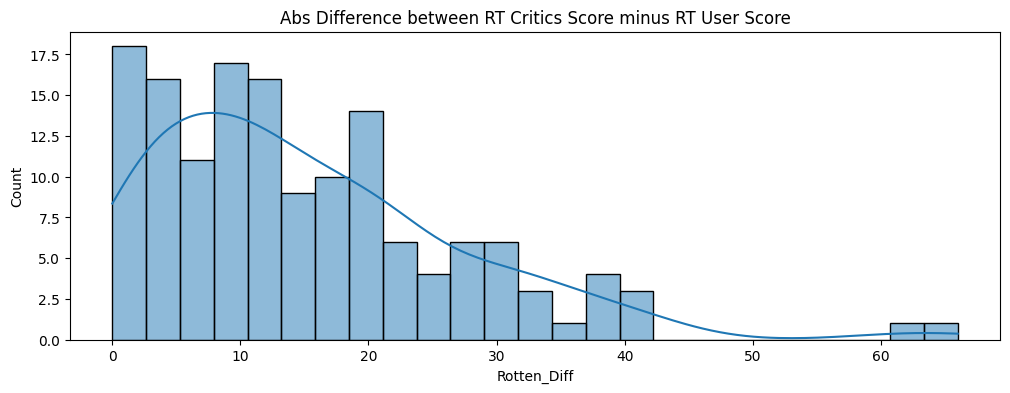

In [32]:
# Distribution of the absolute difference
fig, ax = plt.subplots(figsize=(12, 4))
sns.histplot(data=other, x=abs(other['Rotten_Diff']), kde=True, bins=25, ax=ax)
ax.set_title('Abs Difference between RT Critics Score minus RT User Score');

In [33]:
# 5 films that users liked far more than critics
other[['FILM', 'Rotten_Diff']].sort_values(by='Rotten_Diff', ascending=True).head()

,FILM,Rotten_Diff
3,Do You Believe? (2015),-66
85,Little Boy (2015),-61
105,Hitman: Agent 47 (2015),-42
134,The Longest Ride (2015),-42
125,The Wedding Ringer (2015),-39


In [34]:
# 5 films that critics liked far more than users
other[['FILM', 'Rotten_Diff']].sort_values(by='Rotten_Diff', ascending=False).head()

,FILM,Rotten_Diff
69,Mr. Turner (2014),42
112,It Follows (2015),31
115,While We're Young (2015),31
40,I'll See You In My Dreams (2015),24
145,"Kumiko, The Treasure Hunter (2015)",24


The pattern makes sense: users rate crowd-pleasers like *Do You Believe?* and *Little Boy* much higher than critics do, while critics favour more arthouse films like *Mr. Turner* and *It Follows*.

### Other comparisons

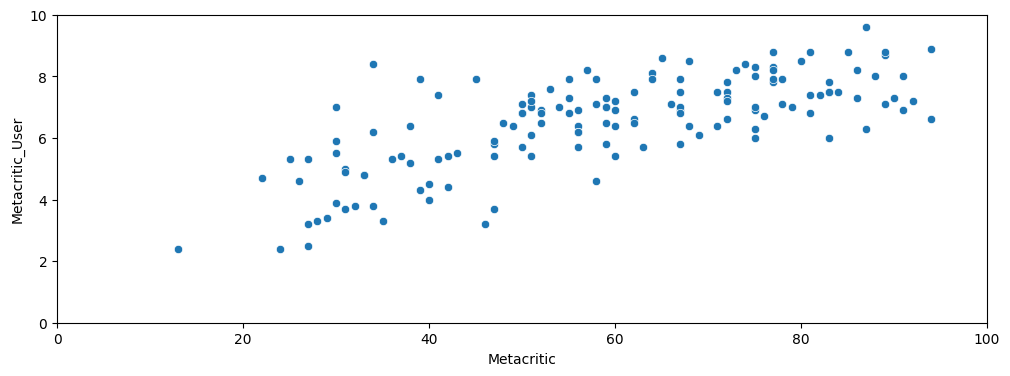

In [35]:
# Metacritic critic score vs. Metacritic user score
plt.figure(figsize=(12,4))
plt.ylim(0, 10)
plt.xlim(0, 100)
sns.scatterplot(data=other, x='Metacritic', y='Metacritic_User');

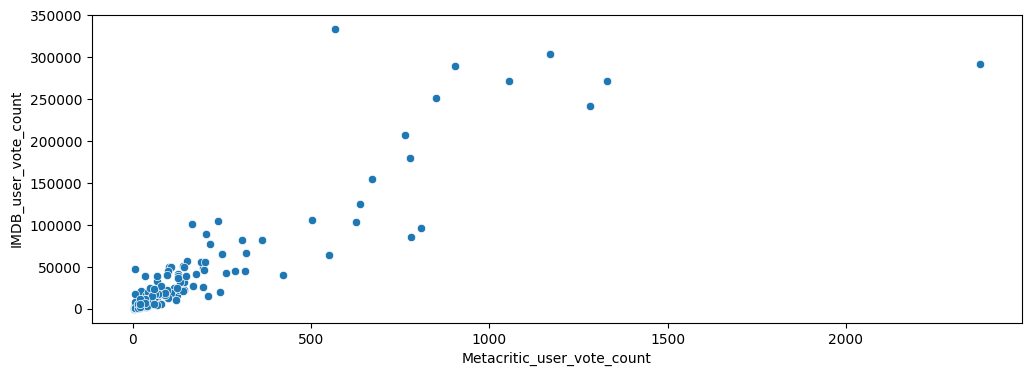

In [36]:
# Metacritic user votes vs. IMDb user votes
plt.figure(figsize=(12,4))
sns.scatterplot(data=other, x='Metacritic_user_vote_count', y='IMDB_user_vote_count');

In [37]:
# Film with the most IMDb votes
other.nlargest(1, 'IMDB_user_vote_count')

,FILM,RottenTomatoes,RottenTomatoes_User,Metacritic,Metacritic_User,IMDB,Metacritic_user_vote_count,IMDB_user_vote_count,Rotten_Diff
14,The Imitation Game (2014),90,92,73,8.2,8.1,566,334164,-2


In [38]:
# Film with the most Metacritic votes
other.nlargest(1, 'Metacritic_user_vote_count')

,FILM,RottenTomatoes,RottenTomatoes_User,Metacritic,Metacritic_User,IMDB,Metacritic_user_vote_count,IMDB_user_vote_count,Rotten_Diff
88,Mad Max: Fury Road (2015),97,88,89,8.7,8.3,2375,292023,9


### Merging the two datasets

In [39]:
# Inner join on film title, so we keep only films present in both datasets
df = pd.merge(fandago, other, how='inner', on='FILM')

In [40]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145 entries, 0 to 144
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   FILM                        145 non-null    object 
 1   STARS                       145 non-null    float64
 2   RATING                      145 non-null    float64
 3   VOTES                       145 non-null    int64  
 4   YEAR                        145 non-null    object 
 5   RottenTomatoes              145 non-null    int64  
 6   RottenTomatoes_User         145 non-null    int64  
 7   Metacritic                  145 non-null    int64  
 8   Metacritic_User             145 non-null    float64
 9   IMDB                        145 non-null    float64
 10  Metacritic_user_vote_count  145 non-null    int64  
 11  IMDB_user_vote_count        145 non-null    int64  
 12  Rotten_Diff                 145 non-null    int64  
dtypes: float64(4), int64(7), object(2)


In [41]:
df.head()

,FILM,STARS,RATING,VOTES,YEAR,RottenTomatoes,RottenTomatoes_User,Metacritic,Metacritic_User,IMDB,Metacritic_user_vote_count,IMDB_user_vote_count,Rotten_Diff
0,Fifty Shades of Grey (2015),4.0,3.9,34846,2015,25,42,46,3.2,4.2,778,179506,-17
1,Jurassic World (2015),4.5,4.5,34390,2015,71,81,59,7.0,7.3,1281,241807,-10
2,American Sniper (2015),5.0,4.8,34085,2015,72,85,72,6.6,7.4,850,251856,-13
3,Furious 7 (2015),5.0,4.8,33538,2015,81,84,67,6.8,7.4,764,207211,-3
4,Inside Out (2015),4.5,4.5,15749,2015,98,90,94,8.9,8.6,807,96252,8


The merged data has 145 films (one film from the other dataset had no Fandango match).

The platforms use different scales (0-100, 0-10, 0-5), so I converted everything to a 0-5 scale to compare them fairly.

In [42]:
# Normalise all ratings to a 0-5 scale
df['RT_Norm'] = np.round(df['RottenTomatoes']/20,1)
df['RTU_Norm'] = np.round(df['RottenTomatoes_User']/20,1)
df['Meta_Norm'] = np.round(df['Metacritic']/20,1)
df['Meta_U_Norm'] = np.round(df['Metacritic_User']/2,1)
df['IMDB_Norm'] = np.round(df['IMDB']/2,1)

In [43]:
df.head()

,FILM,STARS,RATING,VOTES,YEAR,RottenTomatoes,RottenTomatoes_User,Metacritic,Metacritic_User,IMDB,Metacritic_user_vote_count,IMDB_user_vote_count,Rotten_Diff,RT_Norm,RTU_Norm,Meta_Norm,Meta_U_Norm,IMDB_Norm
0,Fifty Shades of Grey (2015),4.0,3.9,34846,2015,25,42,46,3.2,4.2,778,179506,-17,1.2,2.1,2.3,1.6,2.1
1,Jurassic World (2015),4.5,4.5,34390,2015,71,81,59,7.0,7.3,1281,241807,-10,3.6,4.0,3.0,3.5,3.6
2,American Sniper (2015),5.0,4.8,34085,2015,72,85,72,6.6,7.4,850,251856,-13,3.6,4.2,3.6,3.3,3.7
3,Furious 7 (2015),5.0,4.8,33538,2015,81,84,67,6.8,7.4,764,207211,-3,4.0,4.2,3.4,3.4,3.7
4,Inside Out (2015),4.5,4.5,15749,2015,98,90,94,8.9,8.6,807,96252,8,4.9,4.5,4.7,4.4,4.3


In [44]:
# Just the rating columns, for plotting
normal = df[['STARS', 'RATING', 'RT_Norm', 'RTU_Norm', 'Meta_Norm', 'Meta_U_Norm', 'IMDB_Norm']]

In [45]:
normal.head()

,STARS,RATING,RT_Norm,RTU_Norm,Meta_Norm,Meta_U_Norm,IMDB_Norm
0,4.0,3.9,1.2,2.1,2.3,1.6,2.1
1,4.5,4.5,3.6,4.0,3.0,3.5,3.6
2,5.0,4.8,3.6,4.2,3.6,3.3,3.7
3,5.0,4.8,4.0,4.2,3.4,3.4,3.7
4,4.5,4.5,4.9,4.5,4.7,4.4,4.3


## 4. Comparing rating distributions

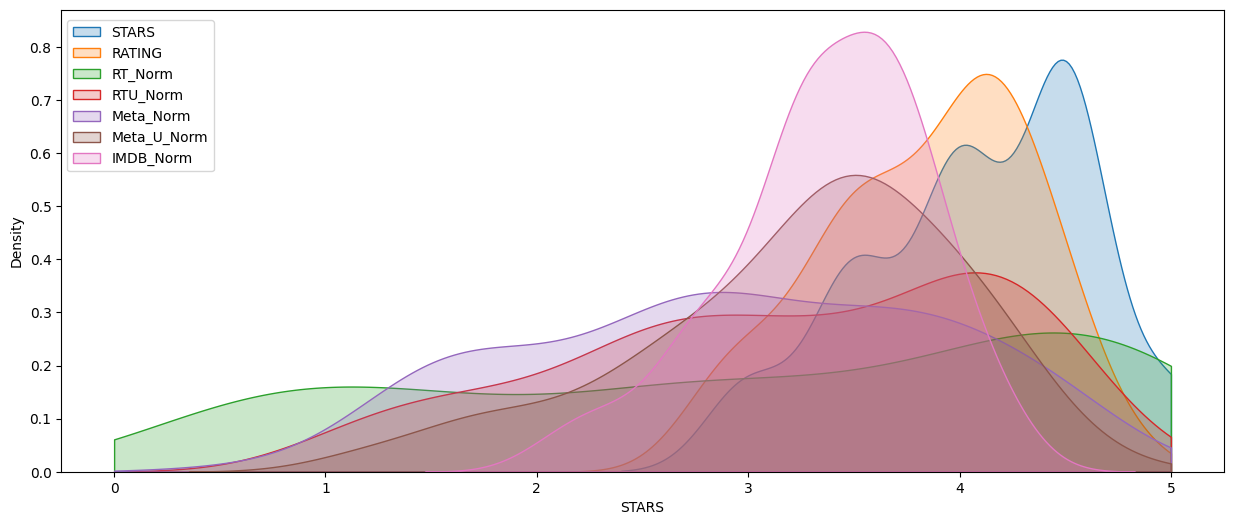

In [46]:
# Distributions of all normalised ratings
plt.figure(figsize=(15,6))
sns.kdeplot(data=normal, x ='STARS', clip=(0, 5), fill=True, label='STARS')
sns.kdeplot(data=normal, x ='RATING', clip=(0, 5), fill=True, label='RATING')
sns.kdeplot(data=normal, x ='RT_Norm', clip=(0, 5), fill=True, label='RT_Norm')
sns.kdeplot(data=normal, x ='RTU_Norm', clip=(0, 5), fill=True, label='RTU_Norm')
sns.kdeplot(data=normal, x ='Meta_Norm', clip=(0, 5), fill=True, label='Meta_Norm')
sns.kdeplot(data=normal, x ='Meta_U_Norm', clip=(0, 5), fill=True, label='Meta_U_Norm')
sns.kdeplot(data=normal, x ='IMDB_Norm', clip=(0, 5), fill=True, label='IMDB_Norm')
plt.legend(loc=(0.005, 0.65));

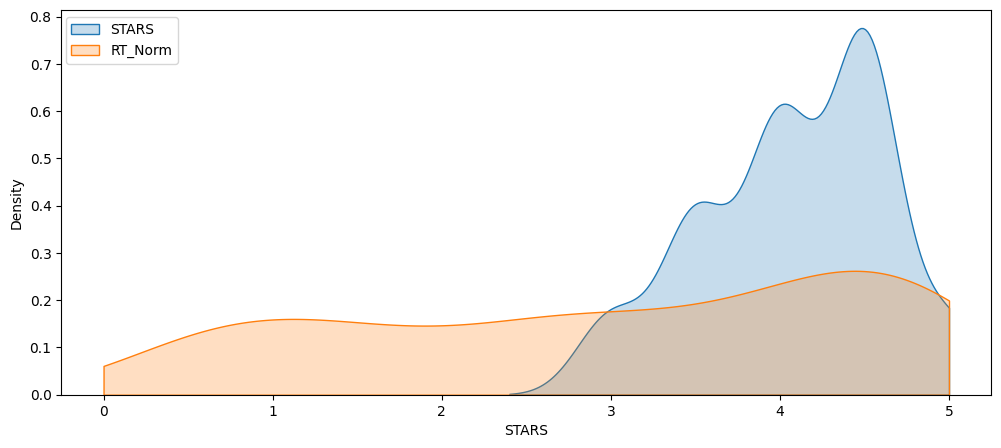

In [47]:
# Fandango stars vs. Rotten Tomatoes critic scores
plt.figure(figsize=(12,5))
sns.kdeplot(data=normal, x ='STARS', clip=(0, 5), fill=True, label='STARS')
sns.kdeplot(data=normal, x ='RT_Norm', clip=(0, 5), fill=True, label='RT_Norm')
plt.legend(loc=(0.005,  0.86));

This is the clearest comparison in the notebook. Rotten Tomatoes critic scores are spread across the whole 0-5 range, including plenty of low scores. Fandango's stars almost never go below 3 and peak around 4.5.

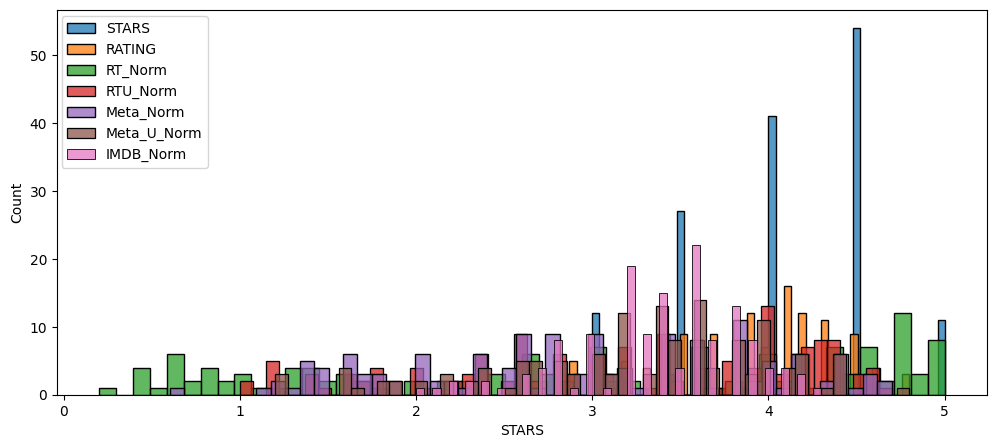

In [48]:
# Same comparison as histograms
plt.figure(figsize=(12,5))
sns.histplot(data=normal, x ='STARS', label='STARS', bins=50)
sns.histplot(data=normal, x ='RATING', label='RATING', bins=50)
sns.histplot(data=normal, x ='RT_Norm', label='RT_Norm', bins=50)
sns.histplot(data=normal, x ='RTU_Norm', label='RTU_Norm', bins=50)
sns.histplot(data=normal, x ='Meta_Norm', label='Meta_Norm', bins=50)
sns.histplot(data=normal, x ='Meta_U_Norm', label='Meta_U_Norm', bins=50)
sns.histplot(data=normal, x ='IMDB_Norm', label='IMDB_Norm', bins=50)
plt.legend(loc=(0.005,  0.59));

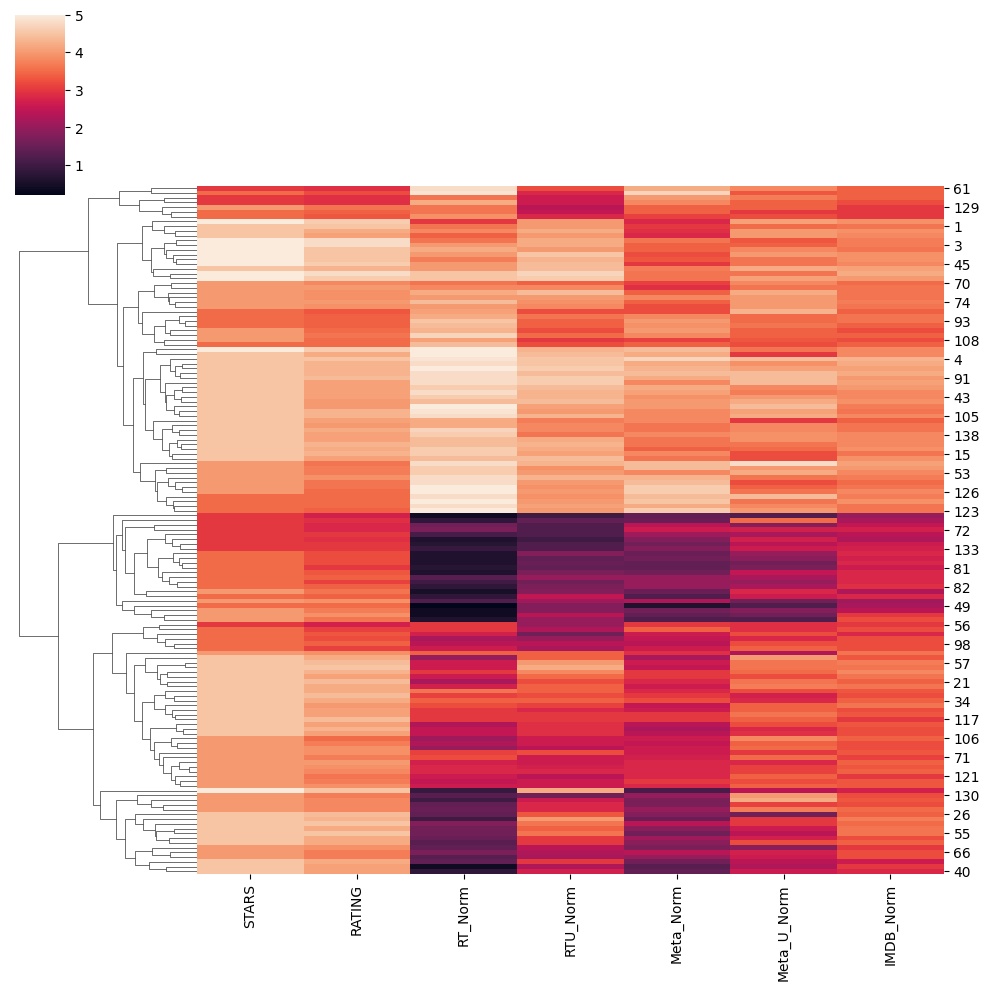

In [49]:
# Clustermap of all normalised ratings
# (rows are films, columns are platforms, so it shows which platforms rate films similarly)
sns.clustermap(data=normal, col_cluster=False);

In [50]:
# Keep the film name so we can look at individual films
norm_films = df[['FILM', 'STARS', 'RATING', 'RT_Norm', 'RTU_Norm', 'Meta_Norm', 'Meta_U_Norm', 'IMDB_Norm']]

In [51]:
norm_films.head()

,FILM,STARS,RATING,RT_Norm,RTU_Norm,Meta_Norm,Meta_U_Norm,IMDB_Norm
0,Fifty Shades of Grey (2015),4.0,3.9,1.2,2.1,2.3,1.6,2.1
1,Jurassic World (2015),4.5,4.5,3.6,4.0,3.0,3.5,3.6
2,American Sniper (2015),5.0,4.8,3.6,4.2,3.6,3.3,3.7
3,Furious 7 (2015),5.0,4.8,4.0,4.2,3.4,3.4,3.7
4,Inside Out (2015),4.5,4.5,4.9,4.5,4.7,4.4,4.3


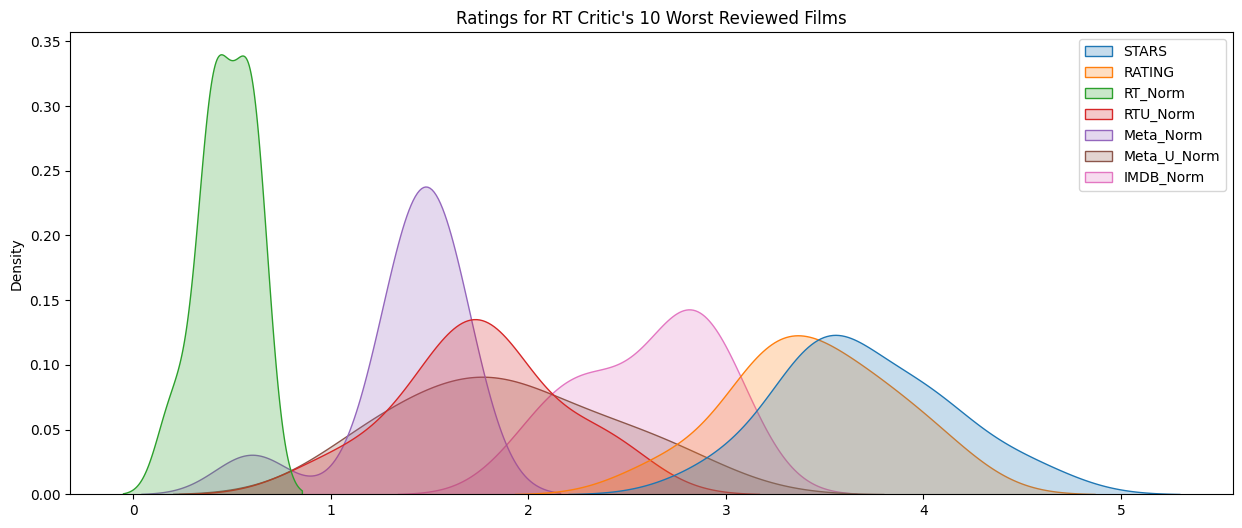

In [52]:
# How do all platforms rate the 10 films with the lowest RT critic scores?
plt.figure(figsize=(15,6))
sns.kdeplot(data=norm_films.nsmallest(10, 'RT_Norm'), fill=True)
plt.title("Ratings for RT Critic's 10 Worst Reviewed Films");

### Case study: *Taken 3*

In [53]:
# Taken 3 across all platforms
norm_films.iloc[25]

,25
FILM,Taken 3 (2015)
STARS,4.5
RATING,4.1
RT_Norm,0.4
RTU_Norm,2.3
Meta_Norm,1.3
Meta_U_Norm,2.3
IMDB_Norm,3.0


In [54]:
# Average of the five non-Fandango ratings for Taken 3
taken3 = norm_films[norm_films['FILM'] == 'Taken 3 (2015)'].iloc[0]
taken3[['RT_Norm', 'RTU_Norm', 'Meta_Norm', 'Meta_U_Norm', 'IMDB_Norm']].mean()

np.float64(1.86)

## 5. Conclusion

The data supports the original FiveThirtyEight finding. Fandango's displayed stars look inflated compared with both its own actual ratings and the other platforms:

- **Displayed stars are never lower than the actual rating.** Most are rounded up by 0.1 to 0.5 stars.
- **Fandango's distribution is shifted upward.** Its stars sit mostly between 3 and 5, while Rotten Tomatoes critic scores cover the full range.
- **Weak films still got high stars.** *Taken 3* showed 4.5 stars on Fandango, while its average across the five other rating sources is about 1.86 out of 5.

**Caveats**
- The merged sample is small (145 films) and almost all from 2015.
- Normalising to a common 0-5 scale is approximate, since critics and users rate on different scales and for different reasons.
- This shows that Fandango's stars are skewed upward, but it can't prove *why* (for example, whether it was done deliberately to sell tickets).